## Chuẩn bị thư viện và môi trường

Sử dụng OpenCV và Scikit-image để phát hiện cạnh; NumPy để xử lý ảnh; Matplotlib và Pandas để hiển thị, tổng hợp kết quả.

In [1]:
import os
# Nếu thiếu thư viện, bỏ dấu # và chạy lệnh sau:
# %pip install opencv-python numpy matplotlib scikit-image scipy pandas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from skimage import feature
from IPython.display import display

SEED = 42
np.random.seed(SEED)
INPUT_DIR = Path("input")
OUTPUT_DIR = Path("results")
INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-image:", __import__("skimage").__version__)

OpenCV: 5.0.0
NumPy: 2.5.4
Scikit-image: 0.26.0


## Ảnh đầu vào

Đọc ảnh màu, chuyển sang ảnh xám để áp dụng Canny. Có thể thay `IMAGE_FILENAME` bằng tên ảnh của bạn.

Ảnh: anh_mau_lab3.png | Kích thước: 560 x 560 | dtype: uint8


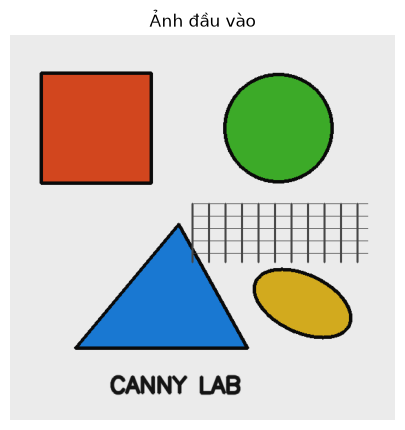

In [2]:
IMAGE_FILENAME = "anh_mau_lab3.png"  # Ví dụ: "anh_cua_toi.jpg"

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
image_files = sorted(p for p in INPUT_DIR.iterdir()
                     if p.is_file() and p.suffix.lower() in extensions)
if not image_files:
    raise FileNotFoundError("Thư mục input/ chưa có ảnh. Hãy chép ảnh vào đây.")

image_path = INPUT_DIR / IMAGE_FILENAME
if not image_path.is_file():
    if len(image_files) == 1:
        image_path = image_files[0]
        print("Không tìm thấy tên mặc định; tự chọn ảnh duy nhất:", image_path.name)
    else:
        raise FileNotFoundError(f"Không tìm thấy {IMAGE_FILENAME}. Hãy sửa IMAGE_FILENAME.")

image = cv2.imdecode(np.fromfile(str(image_path), dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Không đọc được ảnh: {image_path}")

# Giới hạn kích thước để notebook chạy ổn định trên máy cá nhân.
max_side = 800
h, w = image.shape[:2]
scale = min(1.0, max_side / max(h, w))
if scale < 1:
    image = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
height, width = gray.shape
print(f"Ảnh: {image_path.name} | Kích thước: {width} x {height} | dtype: {image.dtype}")

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Ảnh đầu vào")
plt.axis("off")
plt.show()

## Hàm hỗ trợ

Các hàm dưới đây dùng để hiển thị ảnh, lưu kết quả và tính tỷ lệ pixel cạnh. **Tỷ lệ pixel cạnh chỉ mô tả mật độ cạnh, không phải độ chính xác.**

In [3]:
def show_grid(items, cols=2, figsize=(14, 8)):
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, item in zip(axes.flat, items):
        title, img = item[0], item[1]
        cmap = item[2] if len(item) > 2 else None
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap=cmap or "gray", vmin=0, vmax=255 if img.dtype == np.uint8 else None)
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def save_img(name, img):
    path = OUTPUT_DIR / name
    ok, encoded = cv2.imencode(path.suffix or ".png", img)
    if not ok:
        raise IOError(f"Không lưu được {path}")
    encoded.tofile(str(path))
    return path


def edge_density(edges):
    # Tỷ lệ pixel được đánh dấu là cạnh; không phải chỉ số độ chính xác.
    return 100.0 * np.count_nonzero(edges) / edges.size


def gaussian_blur_sigma(gray_img, sigma):
    # Kernel lẻ với bán kính xấp xỉ 4*sigma, gần với phạm vi Gaussian
    # thường dùng trong scipy.ndimage (Scikit-image sử dụng bộ lọc Gaussian này).
    if sigma <= 0:
        return gray_img.copy()
    radius = max(1, int(4 * sigma + 0.5))
    ksize = 2 * radius + 1
    return cv2.GaussianBlur(gray_img, (ksize, ksize), sigma)


def save_figure(name):
    path = OUTPUT_DIR / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Đã lưu biểu đồ:", path)

# I. THỰC HIỆN CANNY BẰNG HAI THƯ VIỆN

Thực hiện phát hiện cạnh bằng `cv2.Canny` của OpenCV và `skimage.feature.canny` của Scikit-image trên cùng ảnh xám. OpenCV không nhận tham số sigma trực tiếp trong `cv2.Canny`, vì vậy Gaussian được áp dụng trước. Scikit-image cho phép truyền sigma trong hàm.

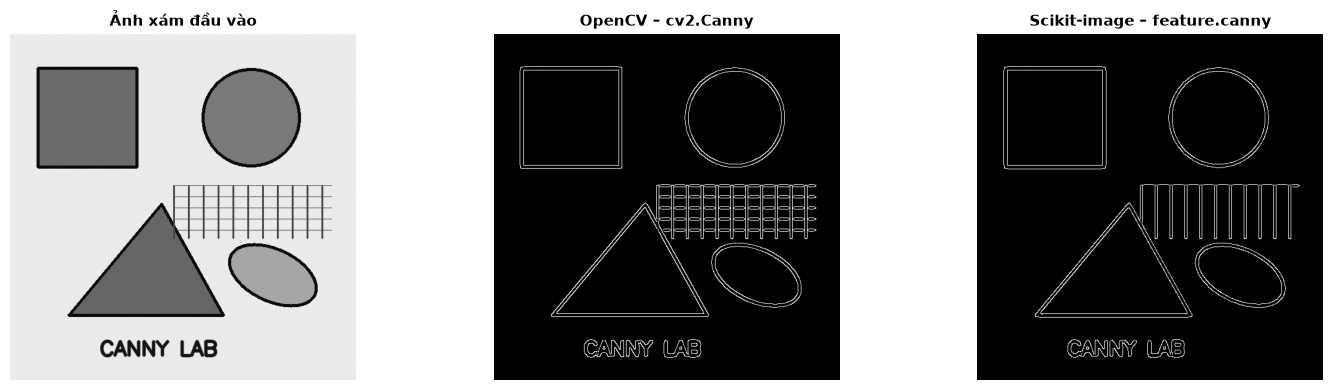

,Thư viện,Tỷ lệ pixel cạnh (%)
0,OpenCV,3.173
1,Scikit-image,2.494


WindowsPath('results/I1_skimage_canny.png')

In [4]:
SIGMA_COMPARE = 1.4
LOW_COMPARE, HIGH_COMPARE = 50, 150
gray_float = gray.astype(np.float32) / 255.0

# OpenCV: làm trơn Gaussian trước, sau đó gọi cv2.Canny.
gray_blur = gaussian_blur_sigma(gray, SIGMA_COMPARE)
edges_cv = cv2.Canny(gray_blur, LOW_COMPARE, HIGH_COMPARE)

# Scikit-image: ảnh float nằm trong [0, 1], ngưỡng được chuẩn hóa tương ứng.
edges_sk = feature.canny(
    gray_float,
    sigma=SIGMA_COMPARE,
    low_threshold=LOW_COMPARE / 255.0,
    high_threshold=HIGH_COMPARE / 255.0
)
edges_sk_u8 = (edges_sk.astype(np.uint8) * 255)

show_grid([
    ("Ảnh xám đầu vào", gray),
    ("OpenCV – cv2.Canny", edges_cv),
    ("Scikit-image – feature.canny", edges_sk_u8)
], cols=3, figsize=(15, 4))

comparison = pd.DataFrame([
    ["OpenCV", edge_density(edges_cv)],
    ["Scikit-image", edge_density(edges_sk_u8)]
], columns=["Thư viện", "Tỷ lệ pixel cạnh (%)"])
display(comparison.round(3))

save_img("I1_opencv_canny.png", edges_cv)
save_img("I1_skimage_canny.png", edges_sk_u8)

**Nhận xét:** Hai thư viện đều tạo bản đồ cạnh nhưng kết quả có thể khác nhau do chi tiết cài đặt và quy ước ngưỡng. Scikit-image nhận ảnh float [0, 1], còn OpenCV ở đây nhận ảnh 8-bit [0, 255], vì vậy ngưỡng được quy đổi theo thang tương ứng. Không yêu cầu hai kết quả phải trùng từng pixel.

# II. THAY ĐỔI THAM SỐ VÀ QUAN SÁT KẾT QUẢ

Khảo sát lần lượt sigma, ngưỡng thấp và ngưỡng cao. Sau đó đối chiếu cấu hình tham chiếu/mặc định với cấu hình tùy chỉnh.

## II.1. Ảnh hưởng của sigma

Sigma điều khiển mức làm trơn Gaussian. Sigma nhỏ giữ nhiều chi tiết nhưng có thể giữ cả nhiễu; sigma lớn làm trơn mạnh hơn nhưng có thể làm mất cạnh nhỏ.

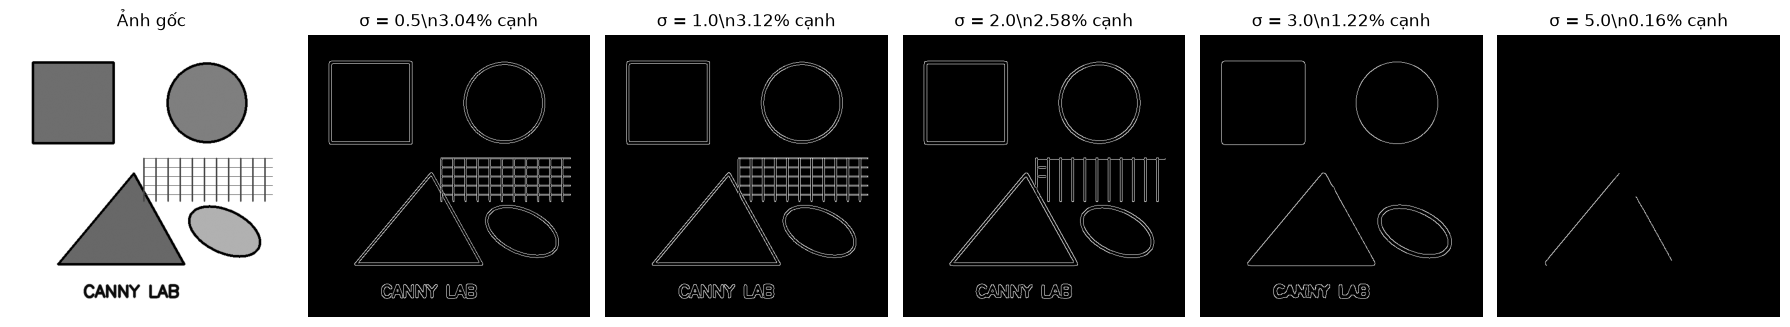

,Sigma,Tỷ lệ pixel cạnh (%)
0,0.5,3.043
1,1.0,3.118
2,2.0,2.580
3,3.0,1.216
4,5.0,0.162


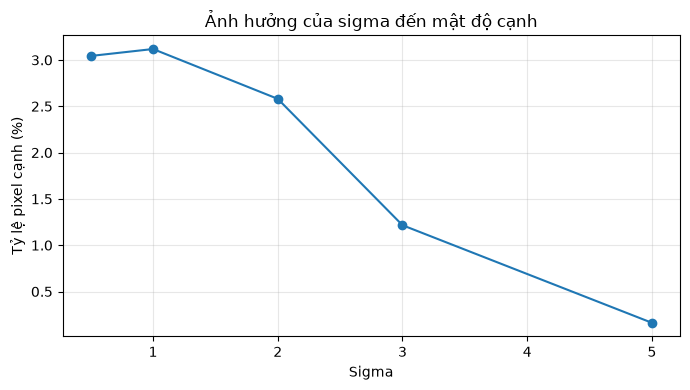

Đã lưu biểu đồ: results\II1_bieu_do_sigma_edge_density.png


<Figure size 640x480 with 0 Axes>

In [5]:
def canny_opencv_sigma(gray_img, sigma, low=50, high=150):
    smoothed = gaussian_blur_sigma(gray_img, sigma)
    return cv2.Canny(smoothed, low, high)

sigmas = [0.5, 1.0, 2.0, 3.0, 5.0]
fig, axes = plt.subplots(1, len(sigmas) + 1, figsize=(18, 4))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
rows = []
for ax, sigma in zip(axes[1:], sigmas):
    edge = canny_opencv_sigma(gray, sigma, 50, 150)
    ratio = edge_density(edge)
    ax.imshow(edge, cmap="gray"); ax.set_title(f"σ = {sigma}\\n{ratio:.2f}% cạnh"); ax.axis("off")
    rows.append([sigma, ratio])
plt.tight_layout(); plt.show()
for sigma in sigmas:
    save_img(f"II1_sigma_{str(sigma).replace('.', '_')}.png", canny_opencv_sigma(gray, sigma, 50, 150))
display(pd.DataFrame(rows, columns=["Sigma", "Tỷ lệ pixel cạnh (%)"]).round(3))

# Biểu đồ mô tả xu hướng mật độ cạnh theo sigma; không phải độ chính xác.
sigma_df = pd.DataFrame(rows, columns=["Sigma", "Tỷ lệ pixel cạnh (%)"])
plt.figure(figsize=(7, 4))
plt.plot(sigma_df["Sigma"], sigma_df["Tỷ lệ pixel cạnh (%)"], marker="o")
plt.xlabel("Sigma")
plt.ylabel("Tỷ lệ pixel cạnh (%)")
plt.title("Ảnh hưởng của sigma đến mật độ cạnh")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
save_figure("II1_bieu_do_sigma_edge_density.png")


## II.2. Ảnh hưởng của ngưỡng thấp và ngưỡng cao

Để quan sát riêng ảnh hưởng của từng ngưỡng, thí nghiệm được chia thành hai nhóm:

- Nhóm A: thay đổi ngưỡng thấp (10, 100, 200, 400), cố định ngưỡng cao ở 500.
- Nhóm B: thay đổi ngưỡng cao (100, 200, 300, 400), cố định ngưỡng thấp ở 50.

Các cặp đều bảo đảm `low < high`. Dải ngưỡng được chọn để quan sát rõ hơn sự thay đổi trên ảnh mẫu có nhiều biên tương phản mạnh.

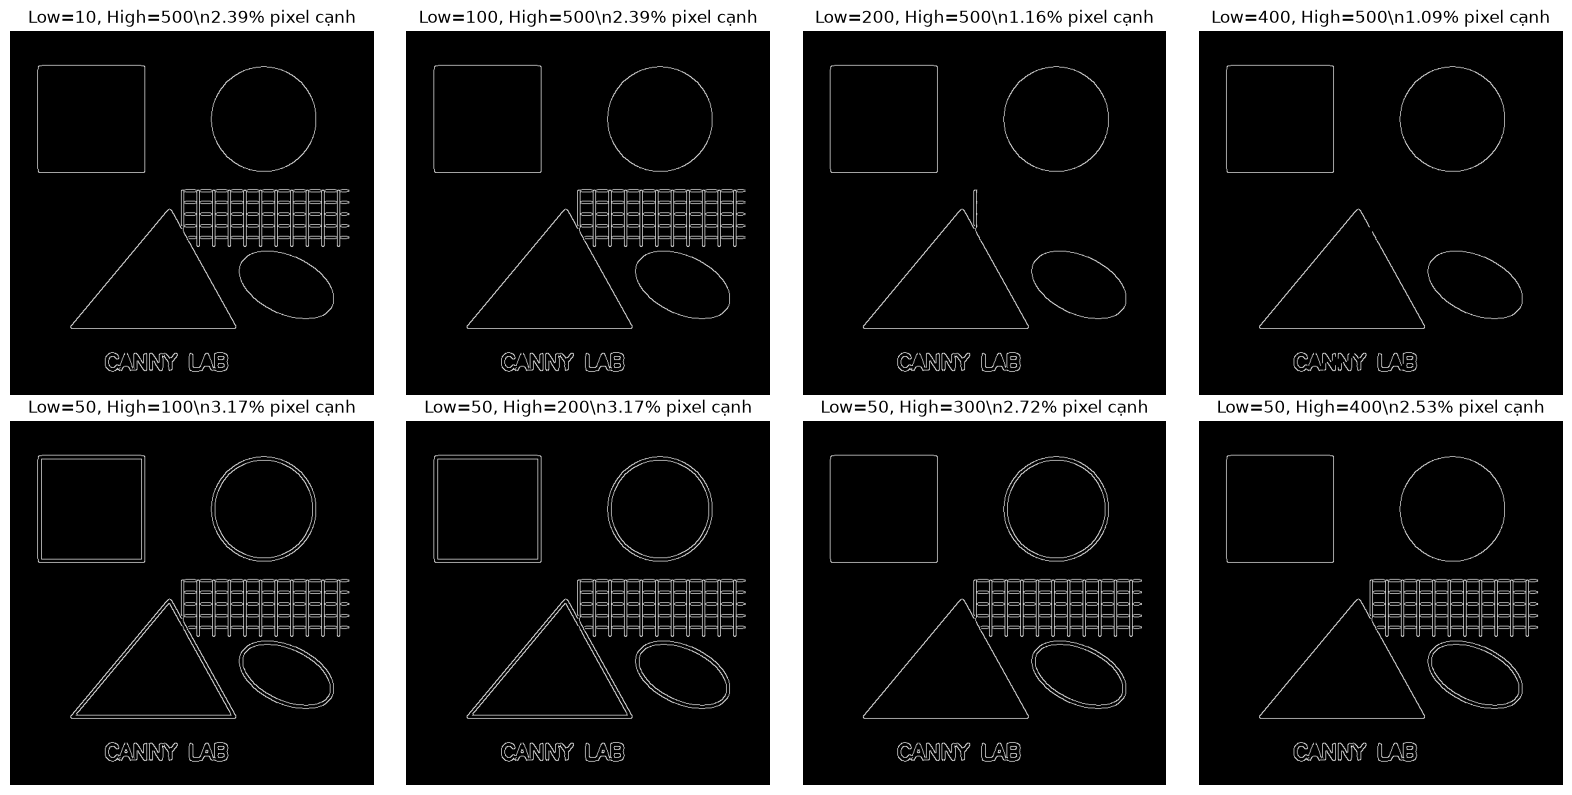

,Ngưỡng thấp,Ngưỡng cao,Tỷ lệ pixel cạnh (%)
0,10,500,2.392
1,100,500,2.390
2,200,500,1.164
3,400,500,1.088
4,50,100,3.173
5,50,200,3.172
6,50,300,2.715
7,50,400,2.526


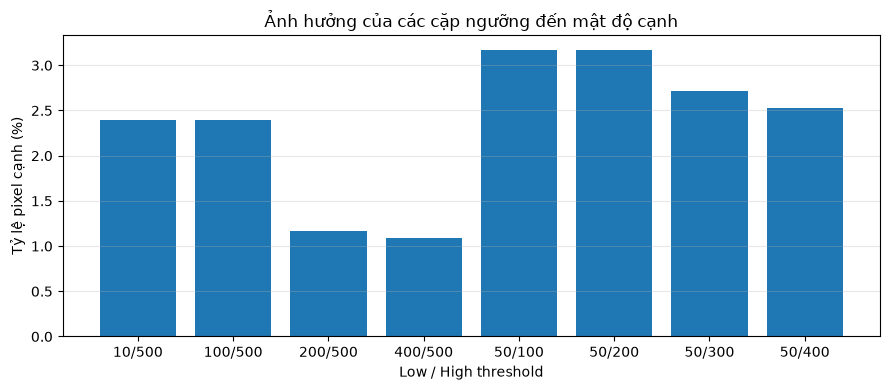

Đã lưu biểu đồ: results\II2_bieu_do_threshold_edge_density.png


<Figure size 640x480 with 0 Axes>

In [6]:
# Nhóm A: thay đổi ngưỡng thấp, giữ ngưỡng cao = 150.
# Nhóm B: thay đổi ngưỡng cao, giữ ngưỡng thấp = 50.
threshold_pairs = [
    (10, 500), (100, 500), (200, 500), (400, 500),
    (50, 100), (50, 200), (50, 300), (50, 400)
]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
rows = []
for ax, (low, high) in zip(axes.ravel(), threshold_pairs):
    edge = canny_opencv_sigma(gray, 1.4, low, high)
    ratio = edge_density(edge)
    ax.imshow(edge, cmap="gray")
    ax.set_title(f"Low={low}, High={high}\\n{ratio:.2f}% pixel cạnh")
    ax.axis("off")
    rows.append([low, high, ratio])
for ax in axes.ravel()[len(threshold_pairs):]:
    ax.axis("off")
plt.tight_layout(); plt.show()
for low, high in threshold_pairs:
    save_img(f"II2_threshold_{low}_{high}.png", canny_opencv_sigma(gray, 1.4, low, high))
display(pd.DataFrame(rows, columns=["Ngưỡng thấp", "Ngưỡng cao", "Tỷ lệ pixel cạnh (%)"]).round(3))

threshold_df = pd.DataFrame(rows, columns=["Ngưỡng thấp", "Ngưỡng cao", "Tỷ lệ pixel cạnh (%)"])
plt.figure(figsize=(9, 4))
labels = [f"{lo}/{hi}" for lo, hi, _ in rows]
plt.bar(labels, [ratio for _, _, ratio in rows])
plt.xlabel("Low / High threshold")
plt.ylabel("Tỷ lệ pixel cạnh (%)")
plt.title("Ảnh hưởng của các cặp ngưỡng đến mật độ cạnh")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
save_figure("II2_bieu_do_threshold_edge_density.png")


## II.3. So sánh giá trị mặc định và tùy chỉnh

`cv2.Canny` bắt buộc truyền hai ngưỡng nên OpenCV không có cặp ngưỡng mặc định để gọi trực tiếp. Vì vậy dùng 100/200 làm **cấu hình tham chiếu**. Với Scikit-image, trước tiên gọi hàm không truyền sigma/ngưỡng để quan sát cấu hình mặc định, sau đó chạy cấu hình tùy chỉnh.

Đây là so sánh giữa các cấu hình tổng thể; riêng trường hợp OpenCV, cả bước làm trơn và ngưỡng đều khác nhau nên không diễn giải bảng này như thí nghiệm chỉ thay đổi một tham số.

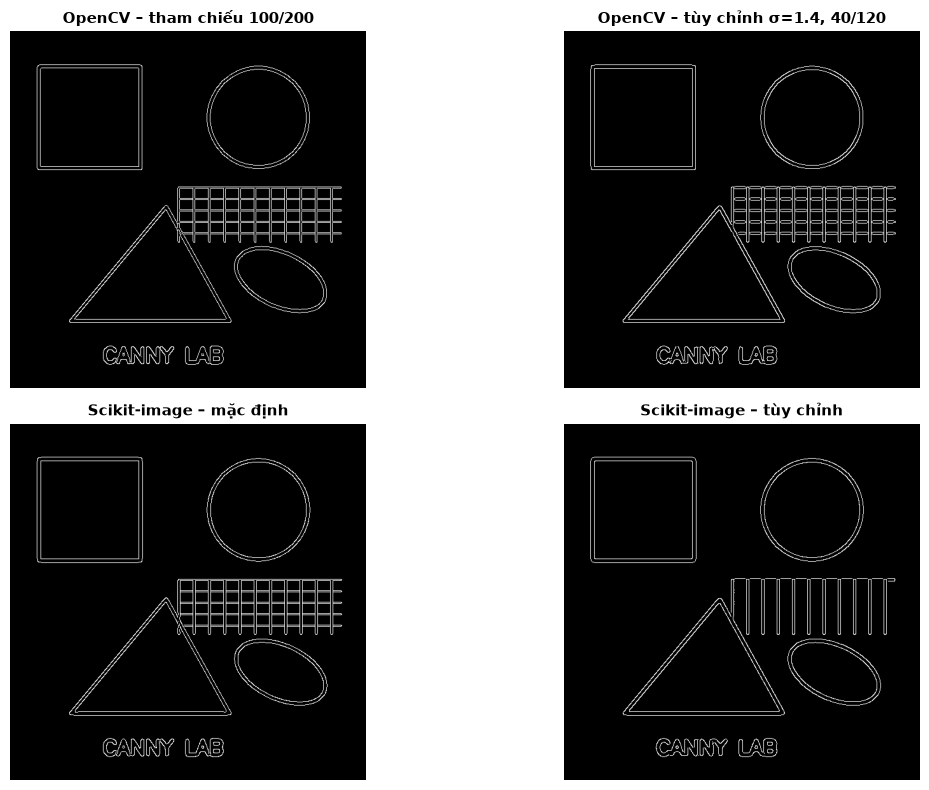

,Cấu hình,Tỷ lệ pixel cạnh (%)
0,OpenCV – tham chiếu,3.024
1,OpenCV – tùy chỉnh,3.173
2,Scikit-image – mặc định,3.060
3,Scikit-image – tùy chỉnh,2.505


WindowsPath('results/II3_skimage_tuy_chinh.png')

In [7]:
# OpenCV: cấu hình tham chiếu 100/200 và cấu hình tùy chỉnh.
cv_reference = cv2.Canny(gray, 100, 200)
cv_custom = canny_opencv_sigma(gray, 1.4, 40, 120)

# Scikit-image: cấu hình mặc định và cấu hình tùy chỉnh.
sk_default = feature.canny(gray_float)
sk_custom = feature.canny(
    gray_float, sigma=2.0,
    low_threshold=30/255.0,
    high_threshold=90/255.0
)

compare_items = [
    ("OpenCV – tham chiếu 100/200", cv_reference),
    ("OpenCV – tùy chỉnh σ=1.4, 40/120", cv_custom),
    ("Scikit-image – mặc định", sk_default.astype(np.uint8) * 255),
    ("Scikit-image – tùy chỉnh", sk_custom.astype(np.uint8) * 255)
]
show_grid(compare_items, cols=2, figsize=(13, 8))

default_custom_table = pd.DataFrame([
    ["OpenCV – tham chiếu", edge_density(cv_reference)],
    ["OpenCV – tùy chỉnh", edge_density(cv_custom)],
    ["Scikit-image – mặc định", edge_density(sk_default.astype(np.uint8) * 255)],
    ["Scikit-image – tùy chỉnh", edge_density(sk_custom.astype(np.uint8) * 255)]
], columns=["Cấu hình", "Tỷ lệ pixel cạnh (%)"])
display(default_custom_table.round(3))

save_img("II3_opencv_tham_chieu.png", cv_reference)
save_img("II3_opencv_tuy_chinh.png", cv_custom)
save_img("II3_skimage_mac_dinh.png", sk_default.astype(np.uint8) * 255)
save_img("II3_skimage_tuy_chinh.png", sk_custom.astype(np.uint8) * 255)

**Nhận xét:** Sigma và hai ngưỡng làm thay đổi lượng chi tiết được giữ lại. Khi sigma hoặc ngưỡng tăng, một số cạnh nhỏ/yếu có thể bị loại; nếu tham số quá thấp, ảnh có thể xuất hiện nhiều cạnh không mong muốn. Cấu hình phù hợp cần được chọn dựa trên ảnh và mục tiêu xử lý.

# III. ÁP DỤNG CANNY CHO CÁC LOẠI ẢNH KHÁC NHAU

Tạo ba trường hợp từ ảnh đầu vào để quan sát có kiểm soát: ảnh có nhiễu, ảnh tương phản thấp và ảnh có nhiều chi tiết. Đây là ảnh mô phỏng để thử nghiệm; nếu có ảnh thực tế thuộc các loại này, có thể thay trực tiếp vào phần tạo ảnh.

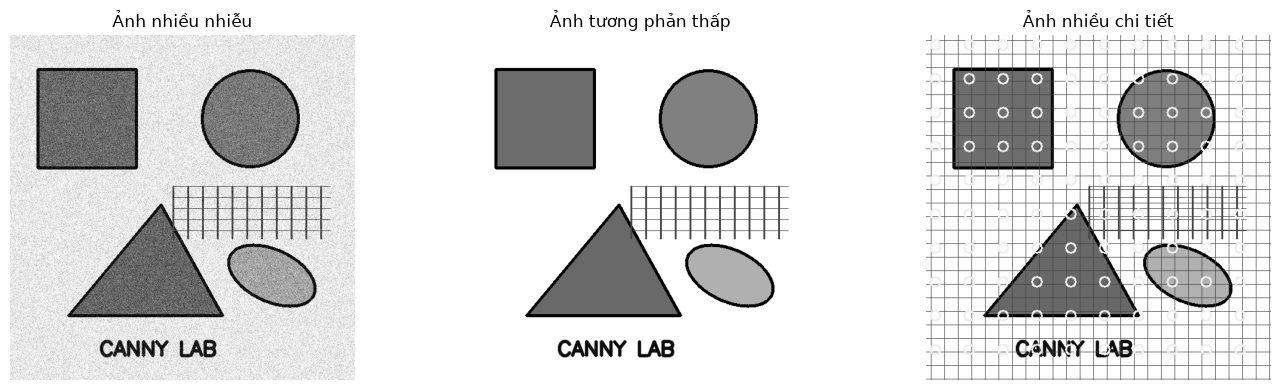

WindowsPath('results/III0_nhieu_chi_tiet.png')

In [8]:
rng = np.random.default_rng(42)

# Ảnh nhiều nhiễu: cộng nhiễu Gaussian.
noise = rng.normal(0, 24, gray.shape)
image_noisy = np.clip(gray.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# Ảnh tương phản thấp: co dải cường độ quanh mức xám 128.
image_low_contrast = np.clip(128 + 0.30 * (gray.astype(np.float32) - 128), 0, 255).astype(np.uint8)

# Ảnh nhiều chi tiết: tạo lưới đường, vòng tròn và họa tiết nhỏ.
image_detailed = gray.copy()
H, W = image_detailed.shape
for x in range(8, W, 22): cv2.line(image_detailed, (x, 0), (x, H-1), 70, 1)
for y in range(8, H, 22): cv2.line(image_detailed, (0, y), (W-1, y), 70, 1)
for x in range(15, W, 55):
    for y in range(15, H, 55): cv2.circle(image_detailed, (x, y), 8, 220, 2)

image_cases = {
    "Ảnh nhiều nhiễu": image_noisy,
    "Ảnh tương phản thấp": image_low_contrast,
    "Ảnh nhiều chi tiết": image_detailed
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, im) in zip(axes, image_cases.items()):
    ax.imshow(im, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("III0_anh_nhieu.png", image_noisy)
save_img("III0_tuong_phan_thap.png", image_low_contrast)
save_img("III0_nhieu_chi_tiet.png", image_detailed)

## III.1. Kết quả Canny trên ba loại ảnh

Dùng cùng một cấu hình Canny (Gaussian sigma = 1.4, low = 50, high = 150) cho cả ba ảnh. Để bảo đảm phép so sánh nhất quán, cùng một hàm Gaussian được dùng ở các phần khảo sát sigma và thử nghiệm ảnh.

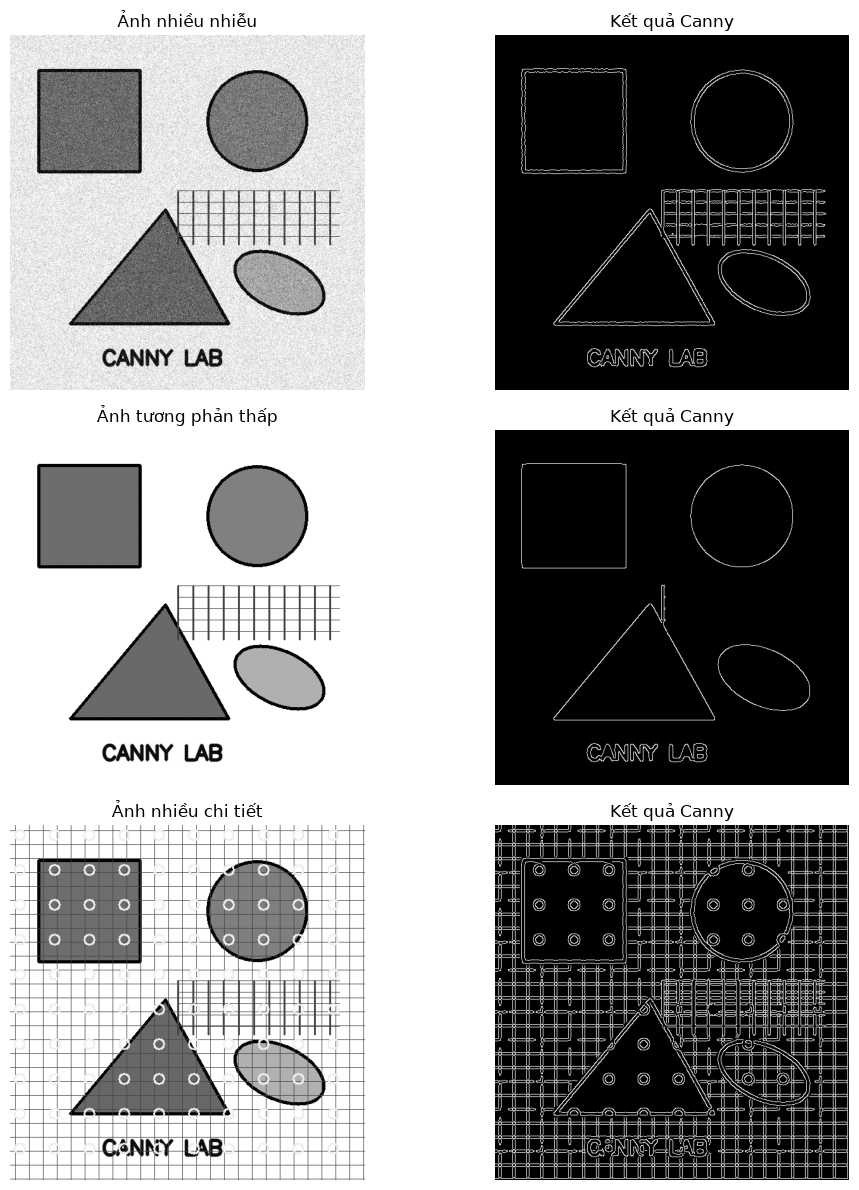

,Loại ảnh,Tỷ lệ pixel cạnh (%)
0,Ảnh nhiều nhiễu,3.118
1,Ảnh tương phản thấp,1.165
2,Ảnh nhiều chi tiết,15.215


In [9]:
image_results = []
density_rows = []

for case_name, case_img in image_cases.items():
    smooth = gaussian_blur_sigma(case_img, 1.4)
    edges = cv2.Canny(smooth, 50, 150)
    image_results.append((case_name, case_img, edges))
    density_rows.append([case_name, edge_density(edges)])
    safe_name = case_name.lower().replace(" ", "_")
    save_img(f"III_{safe_name}_canny.png", edges)

fig, axes = plt.subplots(3, 2, figsize=(11, 12))
for row, (case_name, case_img, edges) in enumerate(image_results):
    axes[row, 0].imshow(case_img, cmap="gray")
    axes[row, 0].set_title(case_name)
    axes[row, 0].axis("off")
    axes[row, 1].imshow(edges, cmap="gray")
    axes[row, 1].set_title("Kết quả Canny")
    axes[row, 1].axis("off")
plt.tight_layout()
plt.show()

image_density_table = pd.DataFrame(
    density_rows,
    columns=["Loại ảnh", "Tỷ lệ pixel cạnh (%)"]
)
display(image_density_table.round(3))

## III.2. Đánh giá kết quả và rút ra kết luận

- **Ảnh nhiều nhiễu:** nhiễu có thể tạo thêm các biến thiên cường độ và sinh cạnh giả. Làm trơn Gaussian trước Canny giúp giảm bớt ảnh hưởng này.
- **Ảnh tương phản thấp:** biên có gradient yếu nên có thể không vượt ngưỡng và bị bỏ sót. Cần thử điều chỉnh ngưỡng thấp/cao.
- **Ảnh nhiều chi tiết:** thường tạo nhiều cạnh gần nhau. Sigma và ngưỡng cần được chọn để cân bằng giữa giữ chi tiết và loại cạnh không cần thiết.

Tỷ lệ pixel cạnh trong bảng chỉ hỗ trợ mô tả mức độ dày đặc của cạnh; không thể dùng riêng chỉ số này để kết luận ảnh nào có độ chính xác cao hơn.

# IV. KẾT HỢP CANNY VỚI PHÂN ĐOẠN VÀ NHẬN DẠNG HÌNH DẠNG

Dùng Canny để lấy biên, morphology closing để nối các khe hở nhỏ, contour để xác định vùng khép kín. Sau đó dùng xấp xỉ đa giác để nhận dạng các hình dạng cơ bản.

## IV.1. Kết hợp Canny với phân đoạn vùng

Ảnh minh họa gồm hình vuông, hình tròn, tam giác và hình chữ nhật. Canny tạo bản đồ biên; morphology closing nối các khe hở nhỏ; contour được trích xuất từ bản đồ biên đã đóng để tạo các vùng khép kín. Đây là ví dụ phân đoạn dựa trên biên, không phải phân đoạn ngữ nghĩa.

Số vùng contour sau lọc diện tích: 4


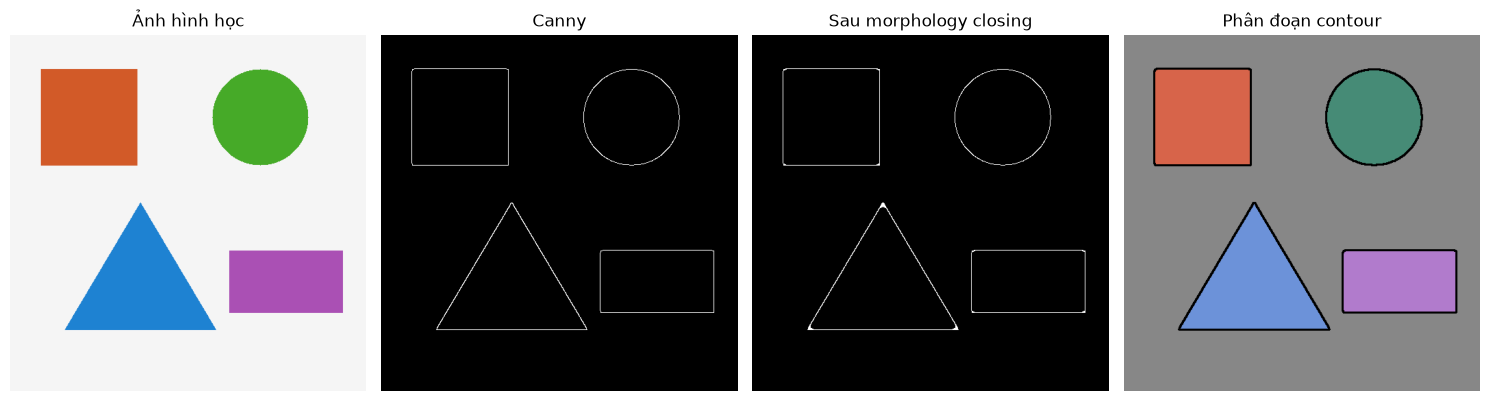

WindowsPath('results/IV1_phan_doan_contour.png')

In [10]:
def tao_anh_hinh_hoc(size=520):
    canvas = np.full((size, size, 3), 245, np.uint8)
    cv2.rectangle(canvas, (45, 50), (185, 190), (40, 90, 210), -1)  # Hình vuông 140 x 140
    cv2.circle(canvas, (365, 120), 70, (40, 170, 70), -1)
    pts = np.array([[80, 430], [190, 245], [300, 430]], np.int32)
    cv2.fillPoly(canvas, [pts], (210, 130, 30))
    cv2.rectangle(canvas, (320, 315), (485, 405), (180, 80, 170), -1)
    return canvas

shape_bgr = tao_anh_hinh_hoc()
shape_gray = cv2.cvtColor(shape_bgr, cv2.COLOR_BGR2GRAY)
shape_blur = cv2.GaussianBlur(shape_gray, (5, 5), 1.4)
shape_edges = cv2.Canny(shape_blur, 40, 120)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
shape_closed = cv2.morphologyEx(shape_edges, cv2.MORPH_CLOSE, kernel, iterations=2)
contours, _ = cv2.findContours(shape_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
min_area = 0.002 * shape_gray.size
contours = [c for c in contours if cv2.contourArea(c) > min_area]

segmentation = np.zeros_like(shape_bgr)
rng = np.random.default_rng(7)
for contour in contours:
    color = tuple(int(v) for v in rng.integers(60, 245, size=3))
    cv2.drawContours(segmentation, [contour], -1, color, thickness=cv2.FILLED)
overlay = cv2.addWeighted(shape_bgr, 0.55, segmentation, 0.45, 0)
cv2.drawContours(overlay, contours, -1, (0, 0, 0), 2)
print(f"Số vùng contour sau lọc diện tích: {len(contours)}")

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, im, title in zip(axes, [shape_bgr, shape_edges, shape_closed, overlay],
                         ["Ảnh hình học", "Canny", "Sau morphology closing", "Phân đoạn contour"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "gray")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("IV1_anh_hinh_hoc.png", shape_bgr)
save_img("IV1_canny.png", shape_edges)
save_img("IV1_morphology_closing.png", shape_closed)
save_img("IV1_phan_doan_contour.png", overlay)

## IV.2. Nhận dạng hình dạng từ contour

Dùng `approxPolyDP` để xấp xỉ đường bao thành đa giác. Số đỉnh giúp nhận dạng tam giác/tứ giác; tỷ lệ chiều rộng/chiều cao giúp phân biệt hình vuông và hình chữ nhật; circularity hỗ trợ nhận diện hình tròn. Hình vuông trong ảnh mẫu được tạo với chiều rộng và chiều cao bằng nhau để nhãn dự đoán có cơ sở hình học.

,Nhãn dự đoán,Diện tích,Số đỉnh xấp xỉ,Circularity
0,Chữ nhật,15095.0,4,0.725
1,Tam giác,20637.0,3,0.557
2,Hình tròn,15414.0,8,0.900
3,Hình vuông,19870.0,4,0.792


Thống kê hình dạng: {'Chữ nhật': 1, 'Tam giác': 1, 'Hình tròn': 1, 'Hình vuông': 1}


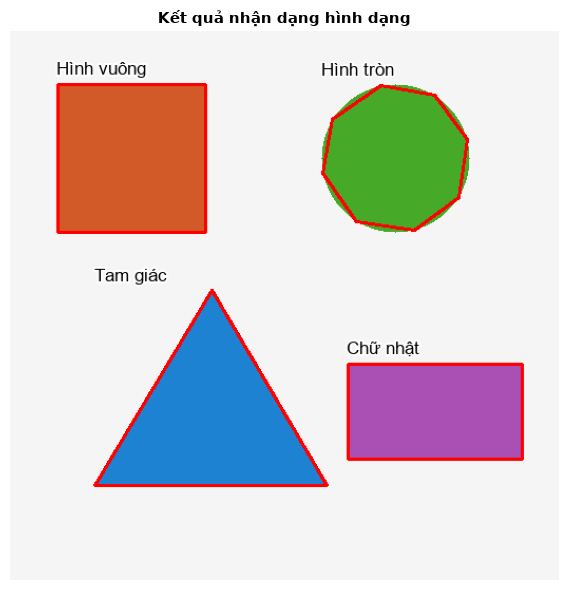

WindowsPath('results/IV2_nhan_dang_hinh_dang.png')

In [11]:
shape_result = shape_bgr.copy()
shape_counts = {}
shape_details = []
label_positions = []

for contour in contours:
    perimeter = cv2.arcLength(contour, True)
    if perimeter <= 0:
        continue
    approx = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
    vertices = len(approx)
    area = cv2.contourArea(contour)
    circularity = 4 * np.pi * area / (perimeter * perimeter + 1e-9)

    if vertices == 3:
        label = "Tam giác"
    elif vertices == 4:
        x, y, w, h = cv2.boundingRect(approx)
        label = "Hình vuông" if 0.90 <= w / max(h, 1) <= 1.10 else "Chữ nhật"
    elif circularity > 0.80:
        label = "Hình tròn"
    elif vertices > 4:
        label = f"Đa giác ({vertices} đỉnh)"
    else:
        label = "Khác"

    shape_counts[label] = shape_counts.get(label, 0) + 1
    x, y, w, h = cv2.boundingRect(contour)
    cv2.drawContours(shape_result, [approx], -1, (0, 0, 255), 2)
    label_positions.append((label, x, max(2, y - 24)))
    shape_details.append([label, round(area, 1), vertices, round(circularity, 3)])

# PIL hỗ trợ chữ tiếng Việt có dấu tốt hơn cv2.putText.
from PIL import Image, ImageDraw, ImageFont
pil_result = Image.fromarray(cv2.cvtColor(shape_result, cv2.COLOR_BGR2RGB))
draw = ImageDraw.Draw(pil_result)
font_candidates = [
    "C:/Windows/Fonts/arial.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf"
]
font_path = next((f for f in font_candidates if os.path.exists(f)), None)
font = ImageFont.truetype(font_path, 17) if font_path else ImageFont.load_default()
for label, x, y in label_positions:
    draw.text((x, y), label, font=font, fill=(0, 0, 0),
              stroke_width=2, stroke_fill=(255, 255, 255))
shape_result = cv2.cvtColor(np.array(pil_result), cv2.COLOR_RGB2BGR)

display(pd.DataFrame(shape_details, columns=["Nhãn dự đoán", "Diện tích", "Số đỉnh xấp xỉ", "Circularity"]))
print("Thống kê hình dạng:", shape_counts)
show_grid([("Kết quả nhận dạng hình dạng", shape_result)], cols=1, figsize=(7, 6))
save_img("IV2_nhan_dang_hinh_dang.png", shape_result)

**Nhận xét:** Canny cung cấp đường biên, không trực tiếp gán nhãn vùng. Morphology closing hỗ trợ khép khe hở nhỏ; contour trích xuất vùng được bao bởi biên; xấp xỉ đa giác và đặc trưng hình học được dùng để nhận dạng các hình cơ bản. Kết quả minh họa đúng bốn hình đã tạo; phương pháp này không đại diện cho nhận dạng mọi vật thể trong ảnh thực tế.

# TỔNG KẾT

| Yêu cầu trong slide | Nội dung đã thực hiện |
|---|---|
| Canny bằng OpenCV và Scikit-image | Đã cài đặt và hiển thị kết quả của hai thư viện |
| Thay đổi sigma, low/high threshold | Đã khảo sát từng tham số bằng ảnh và biểu đồ |
| So sánh mặc định và tùy chỉnh | Đã đối chiếu cấu hình tham chiếu/mặc định với cấu hình tùy chỉnh |
| Ảnh nhiễu, tương phản thấp, nhiều chi tiết | Đã thử nghiệm và nhận xét kết quả |
| Kết hợp phân đoạn vùng | Đã dùng morphology closing và contour |
| Nhận dạng hình dạng | Đã dùng xấp xỉ đa giác và đặc trưng hình học |

**Kết luận chung:** Kết quả Canny phụ thuộc vào chất lượng ảnh và các tham số sigma, ngưỡng thấp, ngưỡng cao. Canny có thể được kết hợp với contour để phân đoạn vùng và nhận dạng một số hình dạng cơ bản.

In [12]:
final_summary = pd.DataFrame([
    ["OpenCV", edge_density(edges_cv)],
    ["Scikit-image", edge_density(edges_sk_u8)],
    ["Ảnh nhiều nhiễu", density_rows[0][1]],
    ["Ảnh tương phản thấp", density_rows[1][1]],
    ["Ảnh nhiều chi tiết", density_rows[2][1]]
], columns=["Trường hợp", "Tỷ lệ pixel cạnh (%)"])
display(final_summary.round(3))

csv_path = OUTPUT_DIR / "lab3_canny_tong_hop.csv"
final_summary.to_csv(csv_path, index=False, encoding="utf-8-sig")
print("Đã lưu bảng tổng hợp:", csv_path)
print("Số vùng contour tìm được:", len(contours))
print("Kết quả nhận dạng hình dạng:", shape_counts)
print("Toàn bộ ảnh kết quả được lưu tại:", OUTPUT_DIR.resolve())

,Trường hợp,Tỷ lệ pixel cạnh (%)
0,OpenCV,3.173
1,Scikit-image,2.494
2,Ảnh nhiều nhiễu,3.118
3,Ảnh tương phản thấp,1.165
4,Ảnh nhiều chi tiết,15.215


Đã lưu bảng tổng hợp: results\lab3_canny_tong_hop.csv
Số vùng contour tìm được: 4
Kết quả nhận dạng hình dạng: {'Chữ nhật': 1, 'Tam giác': 1, 'Hình tròn': 1, 'Hình vuông': 1}
Toàn bộ ảnh kết quả được lưu tại: D:\python\Computer Vision\lab3\results


## Tài liệu tham khảo

- Slide bài tập thực hành Canny Edge Detector do giảng viên cung cấp, trang 26.
- OpenCV Documentation – Canny Edge Detection.
- Scikit-image Documentation – `skimage.feature.canny`.